In [23]:
# !pip install pandas

  Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl.metadata (16 kB)
Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl (10.9 MB)


In [24]:
import numpy as np
import pandas as pd

## Preview the clip

In [7]:
clip = np.load("dataset/SoccerNet-GAR/frames/valid/valid/clip_000000.npy", mmap_mode="r")
clip.shape

(16, 224, 224, 3)

In [8]:
import matplotlib.pyplot as plt

In [9]:
def show_clip(path):
    framecount = len(clip)

    fig, axes = plt.subplots(4, 4, figsize=(12, 10))

    for ax in axes.flat:
        ax.axis("off")

    for i in range(framecount):
        axes.flat[i].imshow(clip[i])
        axes.flat[i].set_title(f"Frame {i}")
    
    plt.imshow(clip[0])
    plt.axis('off')
    plt.show()

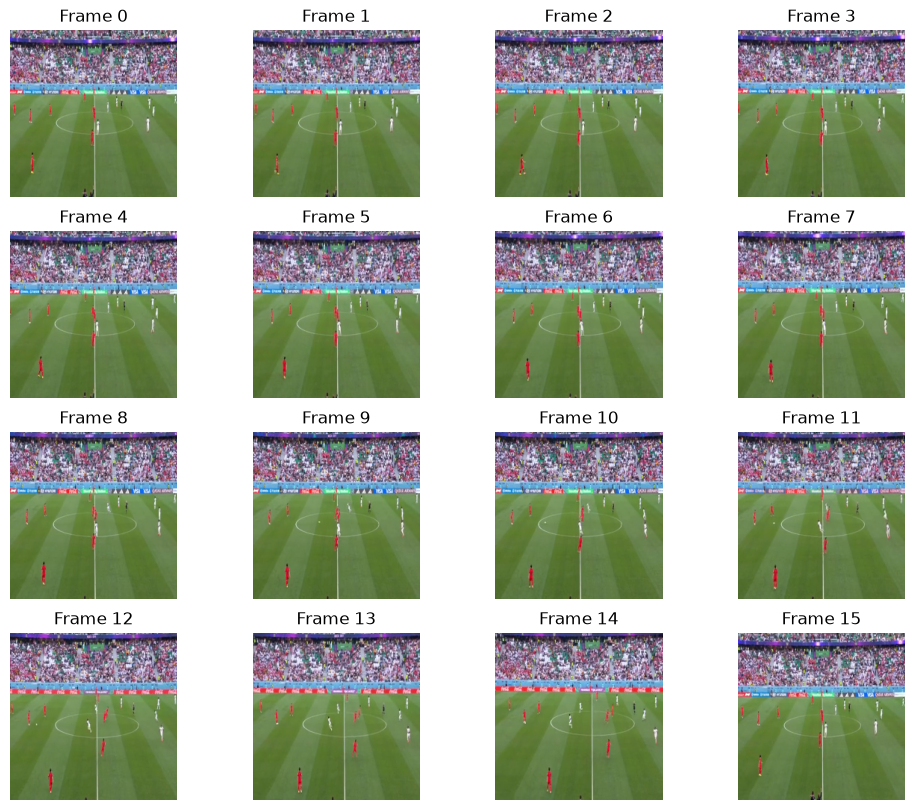

In [10]:
show_clip("dataset/SoccerNet-GAR/frames/valid/valid/clip_000000.npy")

In [15]:
import json

In [16]:
with open("dataset/SoccerNet-GAR/frames/valid/valid.json", "r", encoding="utf-8") as f:
    annotations = json.load(f)

In [18]:
if isinstance(annotations, dict):
    print("Top-level keys:", list(annotations.keys()))

    for key, value in annotations.items():
        print(key, type(value).__name__, len(value) if hasattr(value, "__len__") else "")

Top-level keys: ['version', 'date', 'task', 'modalities', 'dataset_name', 'labels', 'data', 'hf_repo_id', 'hf_branch', 'hf_split', 'hf_format', 'hf_commit']
version str 3
date str 10
task str 21
modalities list 1
dataset_name str 26
labels dict 1
data list 12091
hf_repo_id str 27
hf_branch str 6
hf_split str 5
hf_format str 7
hf_commit str 40


In [19]:
print(json.dumps(annotations["labels"], indent=2))

{
  "action": {
    "type": "single_label",
    "labels": [
      "PASS",
      "HEADER",
      "HIGH PASS",
      "OUT",
      "CROSS",
      "THROW IN",
      "SHOT",
      "PLAYER SUCCESSFUL TACKLE",
      "FREE KICK",
      "GOAL"
    ]
  }
}


In [20]:
print(json.dumps(annotations["data"][0], indent=2))

{
  "id": "valid_000000",
  "inputs": [
    {
      "type": "frames_npy",
      "path": "valid/clip_000000.npy"
    }
  ],
  "labels": {
    "action": {
      "label": "PASS"
    }
  },
  "metadata": {
    "game_id": "3841",
    "game_time": "1 - 00:00",
    "position_ms": 190256,
    "team": "home"
  }
}


In [21]:
print(json.dumps(annotations["data"][2], indent=2))

{
  "id": "valid_000002",
  "inputs": [
    {
      "type": "frames_npy",
      "path": "valid/clip_000002.npy"
    }
  ],
  "labels": {
    "action": {
      "label": "PASS"
    }
  },
  "metadata": {
    "game_id": "3841",
    "game_time": "1 - 00:04",
    "position_ms": 195462,
    "team": "home"
  }
}


In [26]:
df = pd.json_normalize(annotations["data"])

display(df.head())

,id,inputs,labels.action.label,metadata.game_id,metadata.game_time,metadata.position_ms,metadata.team
0,valid_000000,"[{'type': 'frames_npy', 'path': 'valid/clip_00...",PASS,3841,1 - 00:00,190256,home
1,valid_000001,"[{'type': 'frames_npy', 'path': 'valid/clip_00...",PASS,3841,1 - 00:01,192759,home
2,valid_000002,"[{'type': 'frames_npy', 'path': 'valid/clip_00...",PASS,3841,1 - 00:04,195462,home
3,valid_000003,"[{'type': 'frames_npy', 'path': 'valid/clip_00...",PASS,3841,1 - 00:06,198031,home
4,valid_000004,"[{'type': 'frames_npy', 'path': 'valid/clip_00...",PASS,3841,1 - 00:09,201168,home


In [30]:
class_counts = df["labels.action.label"].value_counts()

print(class_counts)


labels.action.label
PASS                        7762
PLAYER SUCCESSFUL TACKLE    1537
HEADER                       870
OUT                          810
THROW IN                     372
CROSS                        314
FREE KICK                    255
SHOT                         135
GOAL                          23
HIGH PASS                     13
Name: count, dtype: int64


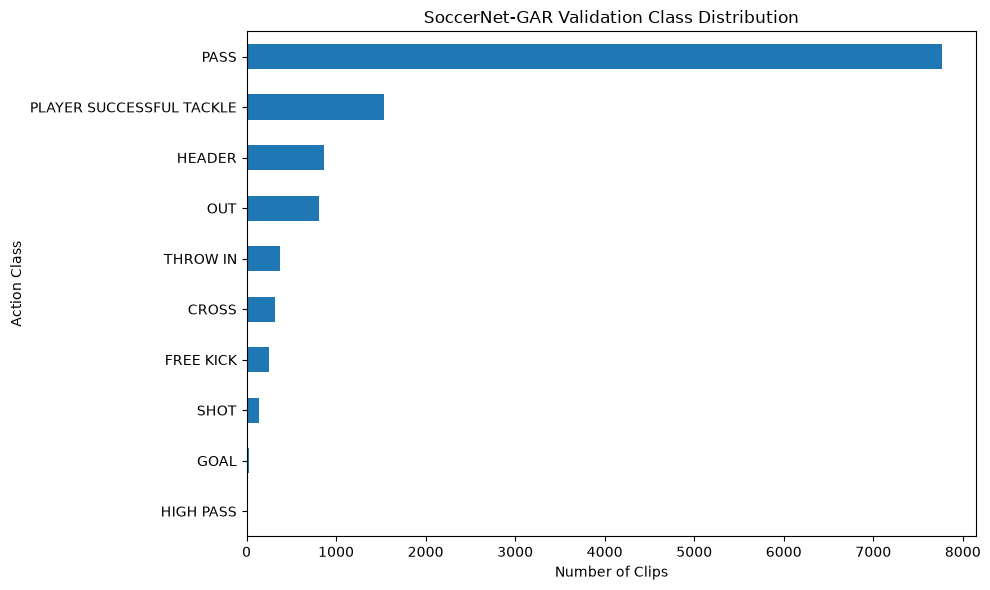

In [31]:
class_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("Number of Clips")
plt.ylabel("Action Class")
plt.title("SoccerNet-GAR Validation Class Distribution")
plt.tight_layout()
plt.show()